In [1]:
pip install xgboost statsmodels scikit-learn

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 3.3 MB/s eta 0:00:15
   - -------------------------------------- 1.8/48.9 MB 3.3 MB/s eta 0:00:15
   -- ------------------------------------- 2.6/48.9 MB 3.4 MB/s eta 0:00:14
   -- ------------------------------------- 3.4/48.9 MB 3.5 MB/s eta 0:00:13
   --- ------------------------------------ 4.2/48.9 MB 3.6 MB/s eta 0:00:13
   ---- ----------------------------------- 5.0/48.9 MB 3.6 MB/s eta 0:00:13
   ---- ----------------------------------- 5.8/48.9 MB 3.6 MB/s eta 0:00:12
   ----- ---------------------------------- 6.6/48.9 MB 3.7 MB/s eta 0:00:12
   ----- ---------------------------------- 7.3/48.9 MB 3.7 MB/s eta 0:00:12
   ------ --------------------------------- 8.4/48.9 MB 3.8 MB/s eta 0:00:11
   ------- -------------------------------- 9.2/48.9 MB 3.8 MB/s eta 0:00:11
   -------- -

In [29]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             average_precision_score, precision_score,
                             recall_score, f1_score)
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor, XGBClassifier

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
COUNTRY = "Zambia"                 # "India" or "Zambia"
SPIKE_TARGET = "spike_next_severe"       # "spike_next" (10%) or "spike_next_severe" (15%)
TRAIN_FRAC = 0.6                  # initial training share
MIN_TRAIN = 48                    # minimum initial training months
REFIT_EVERY = 3                   # retrain every N months
SEED = 42
# ----------------------------------------

THR = {"spike_next": 0.10, "spike_next_severe": 0.15}[SPIKE_TARGET]

In [30]:
data = pd.read_csv(f"features_{COUNTRY.lower()}.csv", parse_dates=["date"])
data = data.sort_values(["commodity", "date"]).reset_index(drop=True)

ID_COLS = ["date", "country", "commodity", "currency", "n_markets", "was_filled"]
TARGET_COLS = ["next_price", "next_mom", "spike_next", "spike_next_severe"]
FEATURES = [c for c in data.columns if c not in ID_COLS + TARGET_COLS + ["price"]]

print(len(FEATURES), "features;", data["commodity"].unique())

20 features; ['Maize (white)']


In [31]:
def reg_metrics(y, yhat):
    mae = mean_absolute_error(y, yhat)
    rmse = np.sqrt(mean_squared_error(y, yhat))
    mape = np.mean(np.abs((y - yhat) / y)) * 100
    return round(mae, 3), round(rmse, 3), round(mape, 2)

def cls_metrics(y_true, y_pred, score):
    return {
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 3),
        "recall":    round(recall_score(y_true, y_pred, zero_division=0), 3),
        "f1":        round(f1_score(y_true, y_pred, zero_division=0), 3),
        "pr_auc":    round(average_precision_score(y_true, score), 3) if y_true.sum() > 0 else np.nan,
    }

In [32]:
def make_models():
    reg = {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "RandomForest": RandomForestRegressor(
            n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
        "XGBoost": XGBRegressor(
            n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
    }
    clf = {
        "Logistic (clf)": make_pipeline(
            StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
        "RandomForest (clf)": RandomForestClassifier(
            n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
            random_state=SEED, n_jobs=-1),
        "XGBoost (clf)": XGBClassifier(
            n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, random_state=SEED, n_jobs=-1, eval_metric="logloss"),
    }
    return reg, clf


def run_commodity(g):
    g = g.sort_values("date").reset_index(drop=True)
    N = len(g)
    start = max(int(N * TRAIN_FRAC), MIN_TRAIN)
    test_idx = np.arange(start, N)

    X = g[FEATURES].values
    price = g["price"].values
    y_price = g["next_price"].values
    y_mom = g["next_mom"].values
    y_cls = g[SPIKE_TARGET].values.astype(int)

    pred_mom, proba = {}, {}

    # ---- baselines ----
    pred_mom["Naive"] = np.zeros(N)                       # next price = this price

    sn = np.full(N, np.nan)
    sn[11:] = price[:-11] / price[11:] - 1                # next price = same month last year
    pred_mom["SeasonalNaive"] = sn

    proba["Persistence"] = (g["mom"].values > THR).astype(float)

    # ---- SARIMA (walk-forward, refit every REFIT_EVERY months) ----
    sar = np.full(N, np.nan)
    res = None
    for k, i in enumerate(test_idx):
        try:
            if res is None or k % REFIT_EVERY == 0:
                res = SARIMAX(price[: i + 1], order=(1, 1, 1),
                              seasonal_order=(1, 0, 0, 12),
                              enforce_stationarity=False,
                              enforce_invertibility=False).fit(disp=False)
            else:
                res = res.append(price[i:i + 1], refit=False)
            fc = float(np.asarray(res.forecast(1))[0])
        except Exception:
            fc, res = price[i], None
        sar[i] = fc / price[i] - 1
    pred_mom["SARIMA"] = sar

    # ---- ML models (expanding window, retrain every REFIT_EVERY months) ----
    reg_models, clf_models = make_models()
    for name in reg_models:
        pred_mom[name] = np.full(N, np.nan)
    for name in clf_models:
        proba[name] = np.full(N, np.nan)

    for b in range(start, N, REFIT_EVERY):
        idx = np.arange(b, min(b + REFIT_EVERY, N))
        tr = np.arange(0, b)

        for name, m in reg_models.items():
            mdl = clone(m).fit(X[tr], y_mom[tr])
            pred_mom[name][idx] = mdl.predict(X[idx])

        ytr = y_cls[tr]
        for name, m in clf_models.items():
            if len(np.unique(ytr)) < 2:
                proba[name][idx] = ytr.mean()
                continue
            mdl = clone(m)
            if isinstance(mdl, XGBClassifier):
                mdl.set_params(scale_pos_weight=(len(ytr) - ytr.sum()) / max(ytr.sum(), 1))
            mdl.fit(X[tr], ytr)
            proba[name][idx] = mdl.predict_proba(X[idx])[:, 1]

    # ---- assemble results on the test period ----
    base = pd.DataFrame({
        "date": g["date"], "commodity": g["commodity"], "price": price,
        "y_true_price": y_price, "y_true_spike": y_cls,
    }).iloc[test_idx]

    frames = []
    for name, pm in pred_mom.items():
        f = base.copy()
        f["model"] = name
        f["y_pred_price"] = f["price"] * (1 + pm[test_idx])
        f["score"] = pm[test_idx]                          # predicted % change
        f["y_pred_spike"] = (f["score"] > THR).astype(int)
        frames.append(f)
    for name, pr in proba.items():
        f = base.copy()
        f["model"] = name
        f["y_pred_price"] = np.nan
        f["score"] = pr[test_idx]                          # spike probability
        f["y_pred_spike"] = (f["score"] >= 0.5).astype(int)
        frames.append(f)
    return pd.concat(frames)

In [33]:
all_res = []
for com, g in data.groupby("commodity"):
    print("Running", com, "...")
    all_res.append(run_commodity(g))
results = pd.concat(all_res, ignore_index=True)
results.head()

Running Maize (white) ...


,date,commodity,price,y_true_price,y_true_spike,model,y_pred_price,score,y_pred_spike
0,2013-11-01,Maize (white),1.5556,1.6667,0,Naive,1.5556,0.0,0
1,2013-12-01,Maize (white),1.6667,1.7778,0,Naive,1.6667,0.0,0
2,2014-01-01,Maize (white),1.7778,1.7778,0,Naive,1.7778,0.0,0
3,2014-02-01,Maize (white),1.7778,1.9444,0,Naive,1.7778,0.0,0
4,2014-03-01,Maize (white),1.9444,2.0000,0,Naive,1.9444,0.0,0


In [34]:
reg_rows = []
for (com, model), s in results.dropna(subset=["y_pred_price"]).groupby(["commodity", "model"]):
    mae, rmse, mape = reg_metrics(s["y_true_price"].values, s["y_pred_price"].values)
    reg_rows.append({"commodity": com, "model": model, "n_test": len(s),
                     "MAE": mae, "RMSE": rmse, "MAPE_%": mape})

reg_table = pd.DataFrame(reg_rows).sort_values(["commodity", "MAE"]).reset_index(drop=True)
reg_table

,commodity,model,n_test,MAE,RMSE,MAPE_%
0,Maize (white),RandomForest,79,0.169,0.240,8.26
1,Maize (white),Ridge,79,0.179,0.251,8.79
2,Maize (white),XGBoost,79,0.180,0.238,8.95
3,Maize (white),Naive,79,0.184,0.278,8.67
4,Maize (white),SARIMA,79,0.201,0.286,9.71
5,Maize (white),SeasonalNaive,79,0.592,0.803,25.01


In [35]:
cls_rows = []
for (com, model), s in results.groupby(["commodity", "model"]):
    m = cls_metrics(s["y_true_spike"].values, s["y_pred_spike"].values, s["score"].values)
    cls_rows.append({"commodity": com, "model": model, "n_test": len(s),
                     "n_spikes": int(s["y_true_spike"].sum()),
                     "base_rate": round(s["y_true_spike"].mean(), 3), **m})

cls_table = pd.DataFrame(cls_rows).sort_values(["commodity", "pr_auc"], ascending=[True, False]).reset_index(drop=True)
cls_table

,commodity,model,n_test,n_spikes,base_rate,precision,recall,f1,pr_auc
0,Maize (white),Logistic (clf),79,5,0.063,0.059,0.2,0.091,0.277
1,Maize (white),RandomForest (clf),79,5,0.063,0.000,0.0,0.000,0.253
2,Maize (white),SeasonalNaive,79,5,0.063,0.167,0.4,0.235,0.233
3,Maize (white),XGBoost (clf),79,5,0.063,0.000,0.0,0.000,0.193
4,Maize (white),SARIMA,79,5,0.063,0.000,0.0,0.000,0.191
5,Maize (white),RandomForest,79,5,0.063,0.000,0.0,0.000,0.114
6,Maize (white),XGBoost,79,5,0.063,0.000,0.0,0.000,0.087
7,Maize (white),Ridge,79,5,0.063,0.000,0.0,0.000,0.072
8,Maize (white),Naive,79,5,0.063,0.000,0.0,0.000,0.063
9,Maize (white),Persistence,79,5,0.063,0.000,0.0,0.000,0.063


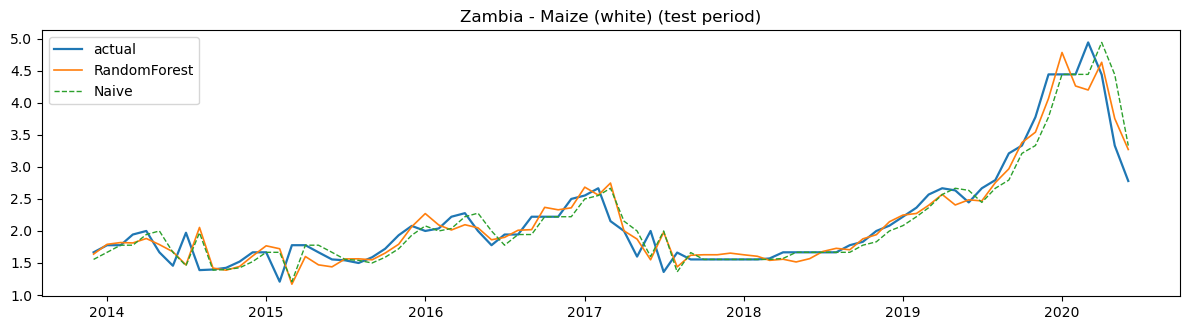

In [36]:
coms = results["commodity"].unique()
fig, axes = plt.subplots(len(coms), 1, figsize=(12, 3.4 * len(coms)))
axes = np.atleast_1d(axes)

for ax, com in zip(axes, coms):
    best = reg_table[reg_table["commodity"] == com].iloc[0]["model"]
    sub = results[results["commodity"] == com]
    a = sub[sub["model"] == best].copy()
    n = sub[sub["model"] == "Naive"]
    x = a["date"] + pd.DateOffset(months=1)          # month being predicted
    ax.plot(x, a["y_true_price"], label="actual", lw=1.6)
    ax.plot(x, a["y_pred_price"], label=f"{best}", lw=1.2)
    ax.plot(x, n["y_pred_price"].values, label="Naive", lw=1, ls="--")
    ax.set_title(f"{COUNTRY} - {com} (test period)")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [37]:
tag = f"{COUNTRY.lower()}_{SPIKE_TARGET}"
results.to_csv(f"predictions_{tag}.csv", index=False)
reg_table.to_csv(f"results_regression_{tag}.csv", index=False)
cls_table.to_csv(f"results_classification_{tag}.csv", index=False)